In [28]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
from statsmodels.stats.outliers_influence import variance_inflation_factor

# This makes it so this notebook file can access python files in ../src/
# project_root = Path.cwd().parent
# sys.path.insert(0, str(project_root))

# And then we can import our functions
from src.config import load_yaml_config
from src.data import load_data
from src.preprocessing import clean_dataset

pd.set_option('display.max_columns', None)

In [2]:
# config = load_yaml_config(project_root / "config.yaml")
config = load_yaml_config("config.yaml")
df = load_data(config["data"]["csv_paths"]["train"])
cleaned = clean_dataset(df, config["cleaning"]["train"])

In [5]:
display(cleaned)

,total_amount_payable,gross_total,net_total,total_tax,total_shipping,total_global_discount,total_line_item_discount,cost,details_count,invoice_count_current_purchase,repeat_purchase_90d,spend_next_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.00,57.15,153.099911,4,1,1,359.04,79,126,2,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0,0.00,1,349.49,2,858.30,2,858.30,660784.0,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.00,34.25,472.943134,32,1,1,592.71,244,616,5,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0,0.00,0,0.00,0,0.00,4,2500.68,189146.0,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.00,3.60,6.097485,1,1,1,423.72,9,610,90,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2,111.27,9,1928.55,28,5290.25,49,7899.80,103940.0,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.00,0.00,408.167275,9,1,0,NaN,97,97,1,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0,0.00,0,0.00,1,270.33,1,270.33,512927.0,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.00,174.95,485.401864,33,1,1,455.73,85,1575,25,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0,0.00,2,184.13,4,2062.50,4,2062.50,122356.0,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6529,3023.34,3761.38,2458.00,565.34,0.0,0.00,1303.38,1099.190000,49,1,1,1467.29,16,196,5,5548.20,1109.640000,1213.808411,254.47,3041.05,45.000000,22.700954,2,562.31,3,3603.36,4,3962.95,5,5548.20,151492.0,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 3,2016-01-24,10007670,-1.579719
6530,1362.26,1723.10,1107.53,254.73,0.0,34.25,581.32,197.514000,16,1,0,NaN,367,367,1,625.91,625.910000,NaN,625.91,625.91,NaN,NaN,0,0.00,0,0.00,0,0.00,0,0.00,975873.0,Maybe Tomorrow Payment 12,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 1,2021-04-13,10007671,-0.576883
6531,4396.55,3574.43,3574.43,822.12,0.0,0.00,0.00,2075.838024,78,1,1,2696.35,77,2331,78,102675.07,1316.347051,1295.241815,3.20,6144.21,29.272727,29.017525,0,0.00,2,2214.29,7,14817.28,13,27824.52,755628.0,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 2,2022-03-19,10007672,0.528377
6532,452.07,483.60,367.54,84.53,0.0,0.00,116.06,265.159468,7,1,1,7051.17,14,874,34,35318.25,1038.772059,1256.647055,3.35,5019.81,26.060606,25.290734,1,1241.86,5,1855.15,9,4922.16,14,12484.20,703834.0,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 1,2019-03-23,10007673,1.012809


In [6]:
cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 40 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   total_amount_payable            6469 non-null   float64       
 1   gross_total                     6469 non-null   float64       
 2   net_total                       6469 non-null   float64       
 3   total_tax                       6469 non-null   float64       
 4   total_shipping                  6469 non-null   float64       
 5   total_global_discount           6469 non-null   float64       
 6   total_line_item_discount        6469 non-null   float64       
 7   cost                            6469 non-null   float64       
 8   details_count                   6469 non-null   Int64         
 9   invoice_count_current_purchase  6469 non-null   Int64         
 10  repeat_purchase_90d             6534 non-null   Int64         
 11  spend_next_90d 

In [13]:
# Check the percentage of missing values for each column:
round(cleaned.isna().sum() / len(cleaned) * 100, 2)

total_amount_payable               0.99
gross_total                        0.99
net_total                          0.99
total_tax                          0.99
total_shipping                     0.99
total_global_discount              0.99
total_line_item_discount           0.99
cost                               0.99
details_count                      0.99
invoice_count_current_purchase     0.99
repeat_purchase_90d                0.00
spend_next_90d                    47.58
days_since_previous_purchase      13.42
customer_tenure_days               0.99
prior_purchase_count               0.99
prior_total_spend                  0.99
prior_mean_purchase_value         13.44
prior_std_purchase_value          17.03
prior_min_purchase_value          10.22
prior_max_purchase_value          10.22
prior_mean_gap_days               20.26
prior_std_gap_days                22.62
purchase_count_30d                 0.99
spend_30d                          0.99
purchase_count_90d                 0.99


In [14]:
cleaned.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,total_amount_payable,gross_total,net_total,total_tax,total_shipping,total_global_discount,total_line_item_discount,cost,details_count,invoice_count_current_purchase,repeat_purchase_90d,spend_next_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,purchase_date,ID,random_noise
count,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.0,6469.0,6534.0,3425.000000,5657.0,6469.0,6469.0,6469.000000,5.656000e+03,5421.000000,5866.000000,5866.000000,5210.000000,5056.000000,6469.0,6469.000000,6469.0,6469.000000,6469.0,6469.000000,6469.0,6.259000e+03,6534.000000,6469,6534.0,6469.000000
mean,925.556262,886.152705,773.336384,152.219878,1.151427,0.349907,112.466414,328.165040,21.524501,1.066007,0.559229,1921.531650,101.828708,1111.383676,23.457876,18908.348876,2.829810e+06,737.469683,185.462003,2946.378367,96.183383,74.135443,0.600557,457.141009,1.631937,1253.527977,3.374556,2650.599796,6.561601,2.402313e+06,506471.910621,2020-08-04 05:01:37.387540,10003832.50153,-0.022140
min,0.930000,0.830000,0.760000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,1.0,0.0,1.270000,1.0,0.0,0.0,0.000000,3.310000e+00,0.000000,0.930000,3.310000,1.000000,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000e+00,103940.000000,2015-07-11 00:00:00,10000000.0,-3.529210
25%,188.920000,175.740000,154.380000,29.930000,0.000000,0.000000,0.000000,49.050000,4.0,1.0,0.0,318.480000,17.0,308.0,3.0,1505.550000,3.619084e+02,258.560327,15.450000,834.530000,42.864583,32.736068,0.0,0.000000,0.0,0.000000,1.0,149.160000,1.0,6.444750e+02,258332.000000,2018-03-31 00:00:00,10001911.25,-0.677770
50%,476.740000,445.740000,389.910000,79.740000,0.000000,0.000000,13.130000,152.540000,11.0,1.0,1.0,985.740000,57.0,918.0,11.0,6754.310000,7.260781e+02,569.077581,64.340000,1783.240000,68.612500,50.635354,0.0,0.000000,1.0,198.500000,2.0,1117.680000,3.0,2.440100e+03,489625.000000,2020-10-03 00:00:00,10003824.5,-0.045714
75%,1087.670000,1036.700000,903.370000,184.840000,0.000000,0.000000,92.280000,396.061499,29.0,1.0,1.0,2464.560000,119.0,1759.0,27.0,21642.320000,1.096575e+03,981.093653,162.610000,3504.420000,114.000000,78.626119,1.0,338.240000,2.0,1514.560000,3.0,3404.440000,7.0,7.067160e+03,755628.000000,2022-12-18 00:00:00,10005759.75,0.641711
90%,2301.730000,2179.218000,1913.754000,372.432000,4.426000,0.000000,297.286000,812.524091,56.0,1.0,1.0,5092.358000,232.0,2484.0,54.0,51442.608000,1.779288e+03,1539.254083,433.090000,5737.910000,174.428571,138.019536,2.0,1463.348000,4.0,3872.704000,7.0,7252.382000,13.0,1.364666e+04,901016.000000,2024-03-23 00:00:00,10006904.4,1.276995
95%,3398.774000,3251.836000,2838.592000,549.120000,5.750000,0.000000,540.394000,1227.526013,75.0,2.0,1.0,6800.260000,337.2,2904.0,88.0,83478.586000,2.569730e+03,1979.621578,820.700000,8050.330000,263.464286,220.574944,3.0,2528.624000,8.0,5828.656000,16.0,10479.206000,31.0,2.228476e+04,942170.000000,2024-09-20 00:00:00,10007289.35,1.643549
99%,6543.971200,6717.615200,5675.703200,1026.788800,11.800000,7.846400,1369.040000,2382.102043,128.0,2.0,1.0,12115.807600,787.76,3318.0,211.32,158299.744400,5.231169e+03,3163.449043,1905.350000,14433.410000,515.742667,486.335676,6.0,5396.487200,16.0,10875.438800,28.0,19209.804400,53.0,4.088768e+04,984211.670000,2025-01-06 00:00:00,10007595.67,2.326001
max,22297.210000,21578.280000,18127.810000,4169.400000,181.060000,218.490000,4103.440000,7427.400583,423.0,5.0,1.0,25654.330000,3199.0,3506.0,276.0,247865.100000,1.000000e+09,6770.221342,6298.980000,267526.189924,3199.000000,2212.537118,11.0,22297.210000,22.0,30234.880000,37.0,49746.970000,60.0,1.000000e+09,998870.000000,2025-02-15 00:00:00,10007674.0,4.151241


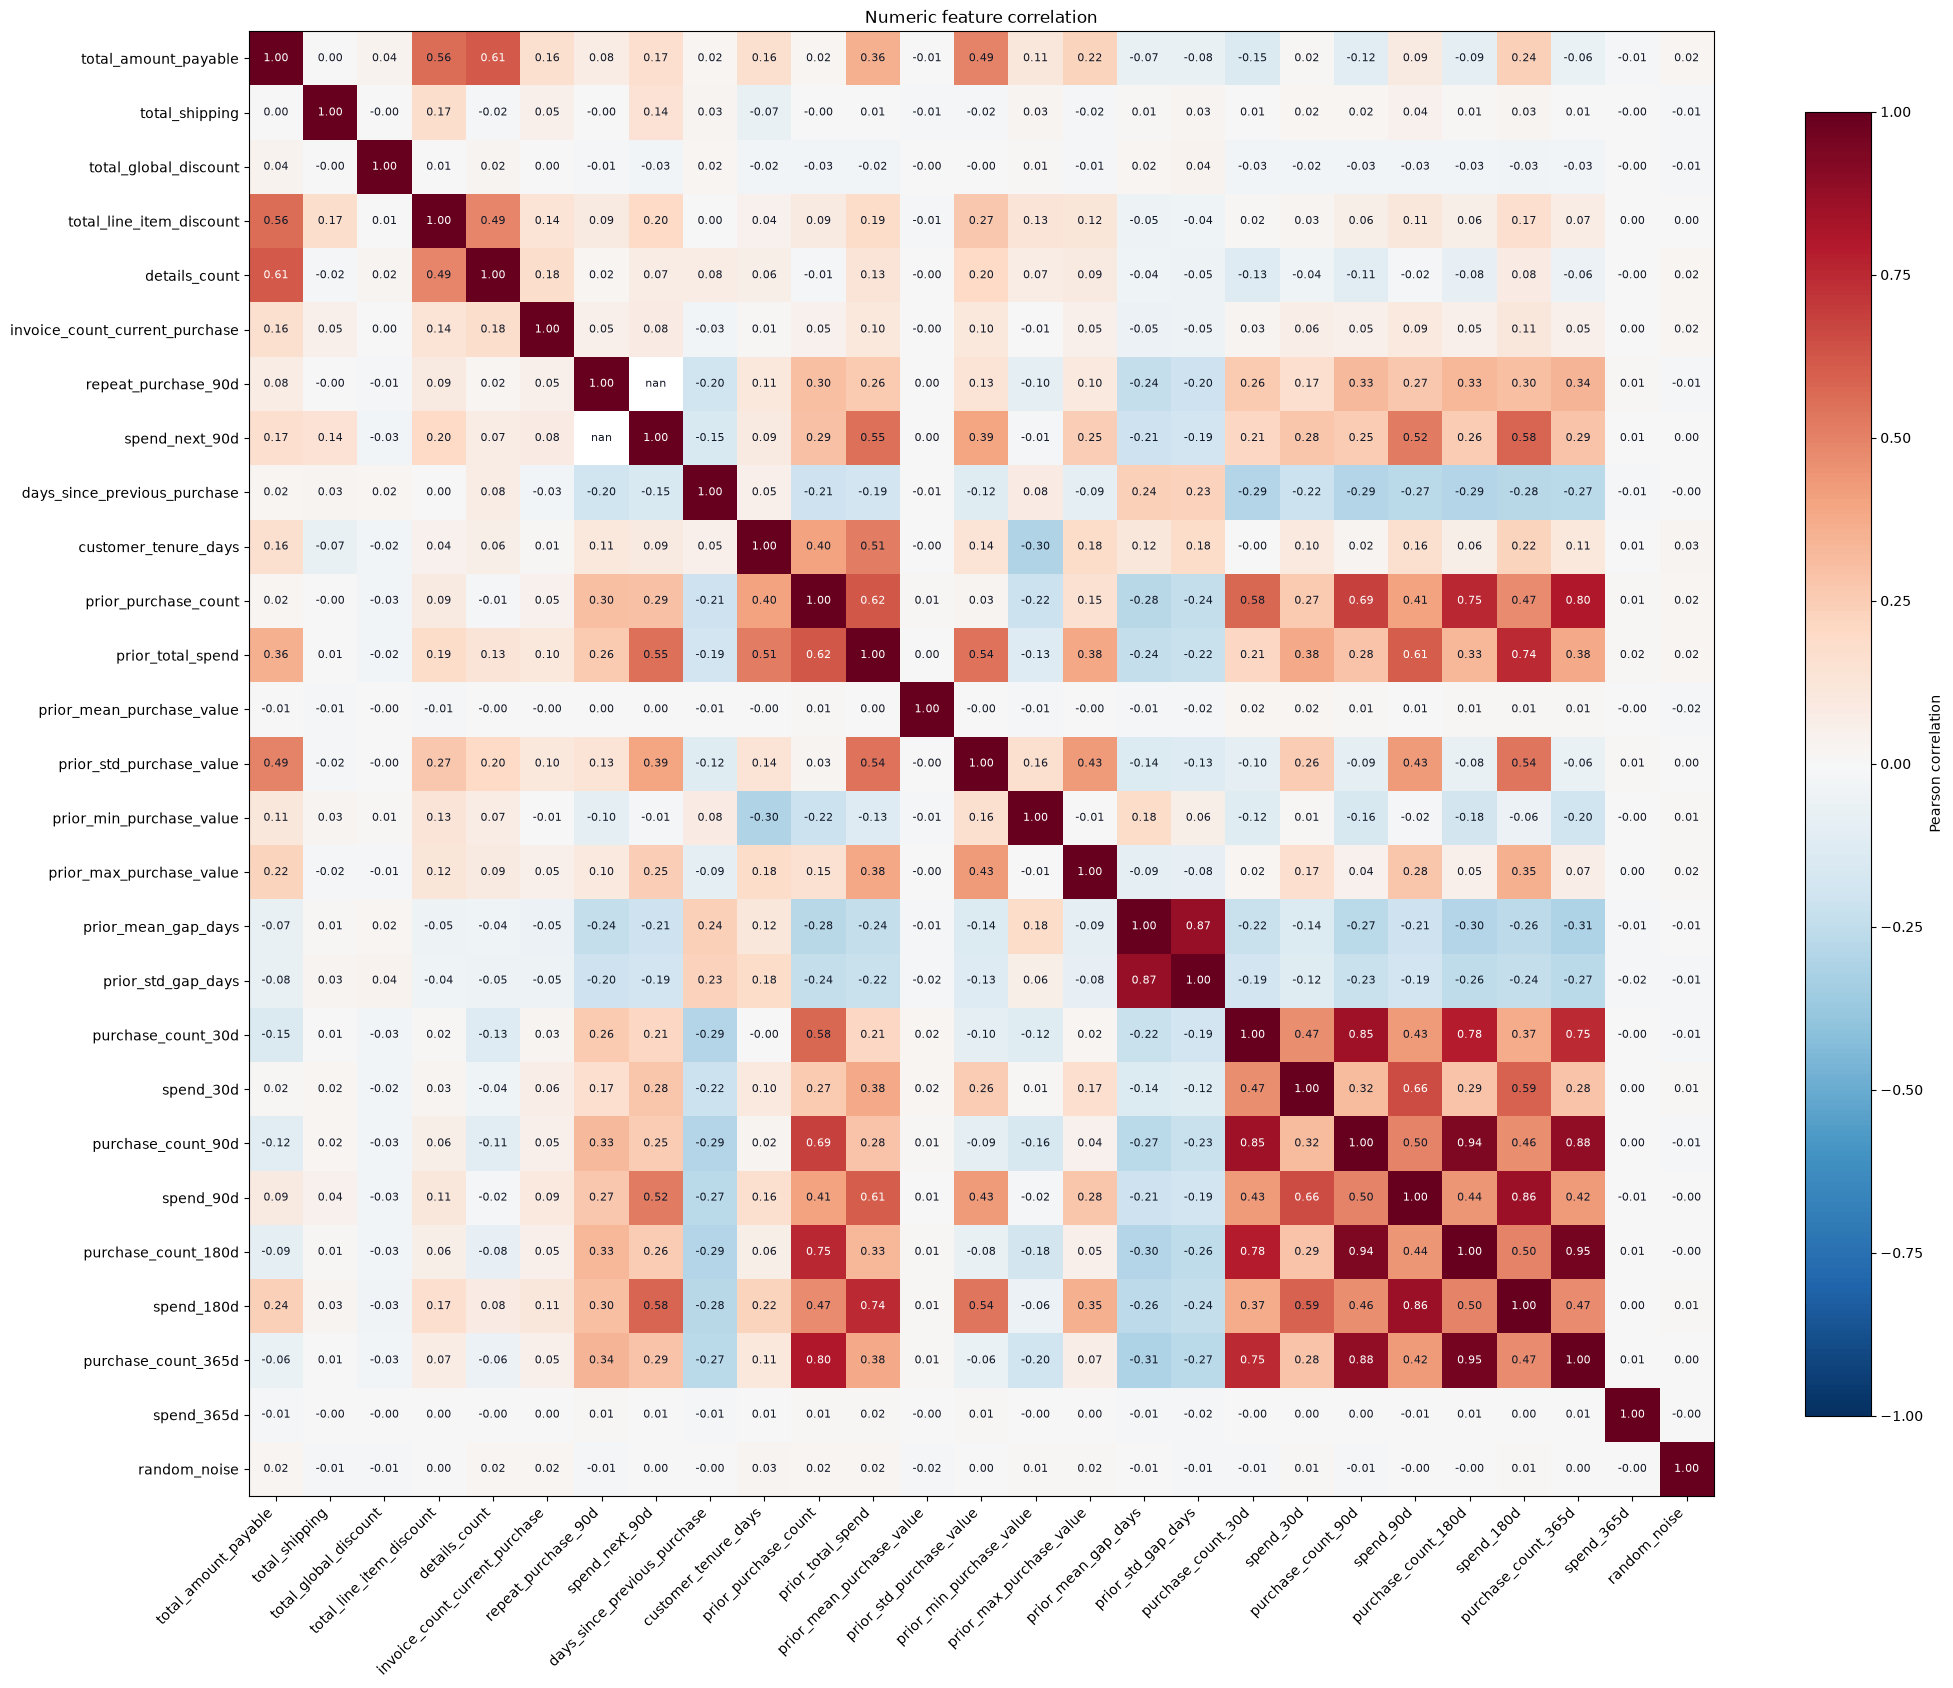

In [20]:
numeric_cols = cleaned.select_dtypes(include="number").columns.tolist()
cols_to_remove = ["ID", "customer_id"]
numeric_cols = [col for col in vif_cols if col not in cols_to_remove]

corr_df = cleaned[numeric_cols].apply(pd.to_numeric, errors="coerce")
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(21, 18))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols)), numeric_cols, rotation=45, ha="right")
ax.set_yticks(range(len(numeric_cols)), numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if abs(v) > 0.6 else "#111827", fontsize=8)
fig.colorbar(im, ax=ax, label="Pearson correlation", shrink=0.8)
ax.set_title("Numeric feature correlation")
plt.tight_layout()
plt.show()

Notes:

- Unsuprisingly, `total_amount_payable` is heavily correlated with `gross_total`, `net_total`, `total_tax`, and `cost`.
- `days_since_previous_purchase` is slightly negatively correlated with `spend_xd` and `purchase_count_xd`, where `x` is 30, 90, 180, and 365. This kinda makes sense since if you buy something more expensive, then your probably gonna hold off a bit on spending more money.

In [29]:
vif_cols = numeric_cols.copy()
cols_to_remove = ["gross_total", "net_total", "total_tax", "cost"]
vif_cols = [col for col in vif_cols if col not in cols_to_remove]

vif_data = cleaned[vif_cols].apply(pd.to_numeric, errors="coerce").dropna()
vif_rows = []
with warnings.catch_warnings():
    # A "rank-deficient" warning here isn't a bug -- it's statsmodels telling us a column
    # is a perfect linear combination of the others, which is exactly what this check is for.
    warnings.simplefilter("ignore")
    for i, col in enumerate(vif_cols):
        vif = variance_inflation_factor(vif_data.values, i)
        vif_rows.append({"column": col, "VIF": f"{vif:,.1f}" if np.isfinite(vif) and vif < 1e6 else "astronomical (perfectly redundant)"})
vif_table = pd.DataFrame(vif_rows).sort_values("column")
vif_table

,column,VIF
9,customer_tenure_days,2.2
8,days_since_previous_purchase,1.3
4,details_count,2.1
5,invoice_count_current_purchase,1.1
15,prior_max_purchase_value,1.2
16,prior_mean_gap_days,5.5
12,prior_mean_purchase_value,1.0
14,prior_min_purchase_value,1.3
10,prior_purchase_count,6.0
17,prior_std_gap_days,4.8


# Clients.csv

In [30]:
clients_df = load_data(config["data"]["csv_paths"]["clients"])

In [31]:
display(clients_df)

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,750900,Country CT10: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Address AD1118: Cell Without a Home,NaN,Excel Is Not A Database Ltd 888,2015
1139,516401,Country CT10: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Address AD1117: Cell Without a Home,NaN,Excel Is Not A Database Ltd 833,2015
1140,404238,Country CT10: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Address AD1119: Cell Without a Home,NaN,Excel Is Not A Database Ltd 636,2015
1141,129129,Country CT10: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Excel Is Not A Database Ltd 787,2015


In [32]:
clients_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          1143 non-null   int64  
 1   country_or_region    1143 non-null   str    
 2   commercial_region    1029 non-null   str    
 3   island               565 non-null    str    
 4   municipality         984 non-null    str    
 5   city                 597 non-null    str    
 6   postal_area          1072 non-null   str    
 7   postal_code          973 non-null    str    
 8   street               545 non-null    str    
 9   address              1137 non-null   str    
 10  customer_type        0 non-null      float64
 11  company_name         1143 non-null   str    
 12  customer_since_year  1143 non-null   int64  
dtypes: float64(1), int64(2), str(10)
memory usage: 116.2 KB


In [34]:
# Check the percentage of missing values for each column:
round(clients_df.isna().sum() / len(clients_df) * 100, 2)

customer_id              0.00
country_or_region        0.00
commercial_region        9.97
island                  50.57
municipality            13.91
city                    47.77
postal_area              6.21
postal_code             14.87
street                  52.32
address                  0.52
customer_type          100.00
company_name             0.00
customer_since_year      0.00
dtype: float64